# 04 · Teste estatístico

**Projeto Integrador** · Jeanderson Soares Mingorança  
**Fase do roadmap:** 4 · Escopo: somente a base comum (DA-017)

**Objetivo:** verificar se as diferenças entre os anos vistas na Fase 3 se sustentam quando se controlam **mês** e **tipo de dia** (útil ou não), com erros robustos à **autocorrelação**, e se são **estáveis** em cenários alternativos.

**Modelo**, por nível (SIN ou subsistema) e indicador diário, estimado por MQO:

$$\text{indicador}_d = \beta_0 + \beta_{2024}\,\mathbb{1}[\text{ano}=2024] + \beta_{2025}\,\mathbb{1}[\text{ano}=2025] + \sum_m \gamma_m\,\mathbb{1}[\text{mês}=m] + \delta\,\text{dia útil}_d + \varepsilon_d$$

- $\beta_{2025}$ é a diferença média de 2025 em relação a 2023, no mesmo mês e no mesmo tipo de dia;
- recorte principal: **maio a dezembro** (DA-018), **sem dias atípicos** (DA-019, DA-020): 730 dias por nível;
- erros-padrão **HAC (Newey-West, 7 defasagens)**, porque dias próximos não são independentes;
- é uma **associação ajustada**, não um efeito causal: o modelo não controla temperatura, hidrologia nem atividade econômica.

Funções em `src/modelagem.py`.

## 1. Ambiente e dados

In [1]:
from pathlib import Path
import sys

# Localiza a raiz do projeto (pasta com pyproject.toml) a partir do diretório atual,
# para que o notebook funcione aberto de notebooks/ ou da raiz.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

PASTA_TABELAS = RAIZ / "resultados" / "tabelas"
PASTA_FIGURAS = RAIZ / "resultados" / "figuras"
PASTA_PROCESSADOS = RAIZ / "dados" / "processados"
for pasta in (PASTA_TABELAS, PASTA_FIGURAS, PASTA_PROCESSADOS):
    pasta.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("Raiz do projeto:", RAIZ.name)

Python: 3.12.10
pandas: 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.2
Raiz do projeto: JeandersonMingoranca_ProjetoIntegrador


In [2]:
from src import modelagem as mod, visualizacao as viz
viz.estilo()
diarios = pd.read_parquet(PASTA_PROCESSADOS / "indicadores_diarios.parquet")
base_horaria = pd.read_parquet(PASTA_PROCESSADOS / "base_horaria.parquet")
principal = mod.recorte_principal(diarios)
principal.groupby(["id_subsistema", "ano"]).size().unstack()

ano,2023,2024,2025
id_subsistema,,,
N,244,243,243
NE,244,243,243
S,244,243,243
SE,244,243,243
SIN,244,243,243


## 2. Modelo principal: diferença ajustada em relação a 2023

In [3]:
coef = mod.estimar_todos(principal, "principal")
tabela_2025 = coef[coef["ano"] == 2025].copy()
tabela_2025["IC 95%"] = tabela_2025.apply(lambda r: f"[{r.ic_inf:,.1f}; {r.ic_sup:,.1f}]", axis=1)
(tabela_2025[["nivel", "indicador", "media_ano_base", "coef", "IC 95%", "p_valor", "var_pct", "n", "r2", "durbin_watson"]]
 .round({"media_ano_base": 1, "coef": 1, "p_valor": 4, "var_pct": 1, "r2": 2, "durbin_watson": 2}))

,nivel,indicador,media_ano_base,coef,IC 95%,p_valor,var_pct,n,r2,durbin_watson
1,SIN,indice_vale,1.0,-0.0,[-0.0; -0.0],0.0000,-2.9,730,0.82,1.95
3,SIN,carga_residual_min,48074.0,-8645.6,"[-9,837.8; -7,453.3]",0.0000,-18.0,730,0.67,0.94
5,SIN,rampa_tarde,21500.7,9749.5,"[8,988.7; 10,510.3]",0.0000,45.3,730,0.62,1.33
7,SIN,maior_rampa_horaria,4856.2,4509.8,"[4,162.1; 4,857.6]",0.0000,92.9,730,0.84,1.37
9,SIN,horas_residual_baixa,1.8,3.2,[2.6; 3.8],0.0000,177.8,730,0.59,1.70
11,SE,indice_vale,1.1,-0.0,[-0.0; -0.0],0.0000,-2.3,730,0.78,1.95
13,SE,carga_residual_min,34584.7,-6899.3,"[-7,720.6; -6,078.1]",0.0000,-19.9,730,0.72,1.03
15,SE,rampa_tarde,12819.4,8585.1,"[8,058.0; 9,112.2]",0.0000,67.0,730,0.77,1.16
17,SE,maior_rampa_horaria,3158.4,2934.2,"[2,674.7; 3,193.8]",0.0000,92.9,730,0.81,1.09
19,SE,horas_residual_baixa,2.6,3.5,[2.8; 4.1],0.0000,133.0,730,0.59,1.51


In [4]:
significativos = (tabela_2025["p_valor"] < 0.05).sum()
print(f"Coeficientes de 2025 significativos a 5%: {significativos} de {len(tabela_2025)}")
print("Não significativos:")
print(tabela_2025.loc[tabela_2025["p_valor"] >= 0.05, ["nivel", "indicador", "coef", "p_valor"]].round(3).to_string(index=False))

Coeficientes de 2025 significativos a 5%: 23 de 25
Não significativos:
nivel            indicador   coef  p_valor
    S horas_residual_baixa -0.167    0.653
    N          indice_vale  0.001    0.671


## 3. Figura 5: diferenças ajustadas com intervalo de confiança

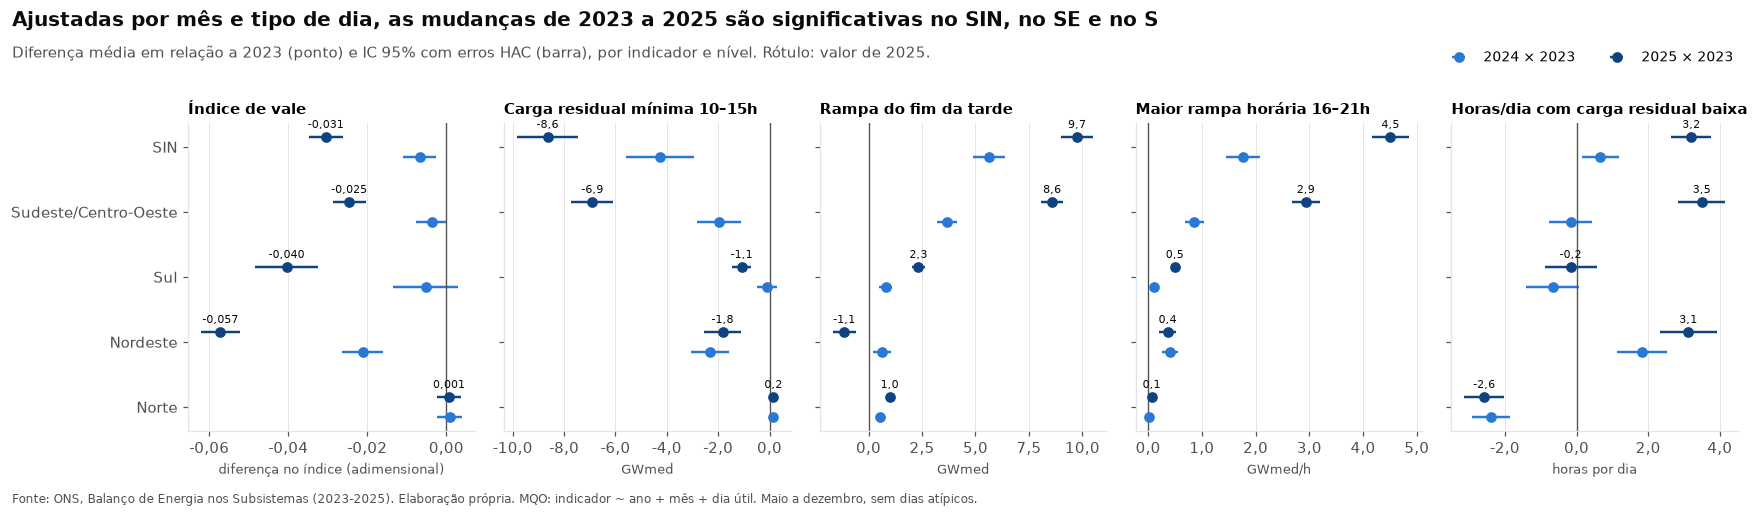

In [5]:
fig = viz.fig_coeficientes(
    coef,
    "Ajustadas por mês e tipo de dia, as mudanças de 2023 a 2025 são significativas no SIN, no SE e no S",
    "Diferença média em relação a 2023 (ponto) e IC 95% com erros HAC (barra), por indicador e nível. Rótulo: valor de 2025.",
    rodape_extra="MQO: indicador ~ ano + mês + dia útil. Maio a dezembro, sem dias atípicos.")
fig.savefig(PASTA_FIGURAS / "04_fig5_diferencas_ajustadas.png", bbox_inches="tight")
plt.show()

**Leitura (Figura 5):** no **SIN**, comparado a 2023 no mesmo mês e tipo de dia, 2025 tem:
- carga residual mínima **8,6 GW menor** (IC 95%: −9,8 a −7,5 GW; −18%);
- rampa do fim da tarde **9,7 GW maior** (+8,99 a +10,5 GW; +45%);
- maior rampa horária **4,5 GW/h maior** (+93%);
- **3,2 h/dia a mais** de carga residual baixa (+2,6 a +3,8 h).

Os intervalos não cruzam o zero, e o padrão se repete no **SE** e, em menor escala, no **S**. O **NE** mostra o vale mais fundo e mais horas de carga residual baixa, mas a rampa **diminui**. O **Norte** tem rampa maior, mas não tem vale mais fundo nem mais horas de carga residual baixa. 2024 fica, em geral, entre 2023 e 2025, ou seja, a mudança é progressiva.

## 4. Sensibilidade: o resultado depende das escolhas?

In [6]:
cenarios = mod.cenarios_sensibilidade(diarios, base_horaria)
estab = mod.estabilidade(cenarios)
print(f"Combinações nível × indicador robustas (mesmo sinal e p < 0,05 nos {estab['cenarios'].iloc[0]} cenários): "
      f"{estab['robusto'].sum()} de {len(estab)}")
estab.round(1)

Combinações nível × indicador robustas (mesmo sinal e p < 0,05 nos 6 cenários): 21 de 25


,nivel,indicador,cenarios,mesmo_sinal,significativo_em,coef_min,coef_max,robusto
0,N,carga_residual_min,6,True,6,147.5,175.8,True
1,N,horas_residual_baixa,6,True,6,-2.6,-2.4,True
2,N,indice_vale,6,False,0,-0.0,0.0,False
3,N,maior_rampa_horaria,6,True,6,27.0,143.1,True
4,N,rampa_tarde,6,True,6,928.7,1005.8,True
5,NE,carga_residual_min,6,True,6,-2494.3,-1658.4,True
6,NE,horas_residual_baixa,6,True,6,3.1,3.3,True
7,NE,indice_vale,6,True,6,-0.1,-0.0,True
8,NE,maior_rampa_horaria,6,False,6,-129.8,561.3,False
9,NE,rampa_tarde,6,True,5,-1294.3,-412.4,False


In [7]:
comparativo = (cenarios[cenarios["ano"] == 2025]
               .pivot_table(index=["nivel", "indicador"], columns="cenario", values="coef")
               [["principal", "janelas -1h", "janelas +1h", "só dias úteis", "com dias atípicos", "HAC 30 defasagens"]])
comparativo.round(1)

cenario                     principal  janelas -1h  janelas +1h  \
nivel indicador                                                   
N     carga_residual_min        150.8        156.3        147.5   
      horas_residual_baixa       -2.6         -2.6         -2.6   
      indice_vale                 0.0          0.0         -0.0   
      maior_rampa_horaria        65.0        143.1         52.3   
      rampa_tarde               987.7        928.7        997.7   
NE    carga_residual_min      -1830.1      -1658.4      -2182.0   
      horas_residual_baixa        3.1          3.1          3.1   
      indice_vale                -0.1         -0.1         -0.0   
      maior_rampa_horaria       362.5        561.3       -129.8   
      rampa_tarde             -1136.8      -1294.3       -824.0   
S     carga_residual_min      -1085.8      -1086.3      -1078.8   
      horas_residual_baixa       -0.2         -0.2         -0.2   
      indice_vale                -0.0         -0.0         -0.0   
      maior_rampa_horaria       495.7        553.9        370.2   
      rampa_tarde              2332.4       2163.4       2296.3   
SE    carga_residual_min      -6899.3      -6821.6      -6934.7   
      horas_residual_baixa        3.5          3.5          3.5   
      indice_vale                -0.0         -0.0         -0.0   
      maior_rampa_horaria      2934.2       3008.8       1442.2   
      rampa_tarde              8585.1       8010.4       8484.1   
SIN   carga_residual_min      -8645.6      -8311.1      -8823.8   
      horas_residual_baixa        3.2          3.2          3.2   
      indice_vale                -0.0         -0.0         -0.0   
      maior_rampa_horaria      4509.8       4407.1       1917.9   
      rampa_tarde              9749.5       8709.3       9730.0   

cenario                     só dias úteis  com dias atípicos  \
nivel indicador                                                
N     carga_residual_min            162.1              175.8   
      horas_residual_baixa           -2.4               -2.6   
      indice_vale                    -0.0                0.0   
      maior_rampa_horaria            27.0               64.0   
      rampa_tarde                  1005.8              965.6   
NE    carga_residual_min          -2494.3            -1848.8   
      horas_residual_baixa            3.3                3.1   
      indice_vale                    -0.1               -0.1   
      maior_rampa_horaria           514.0              371.2   
      rampa_tarde                  -412.4            -1094.9   
S     carga_residual_min          -1224.0            -1092.1   
      horas_residual_baixa           -0.1               -0.2   
      indice_vale                    -0.0               -0.0   
      maior_rampa_horaria           505.7              497.9   
      rampa_tarde                  2563.4             2333.8   
SE    carga_residual_min          -7538.1            -6877.7   
      horas_residual_baixa            4.0                3.5   
      indice_vale                    -0.0               -0.0   
      maior_rampa_horaria          2847.2             2922.6   
      rampa_tarde                  9232.8             8559.0   
SIN   carga_residual_min         -10394.2            -8633.2   
      horas_residual_baixa            2.7                3.2   
      indice_vale                    -0.0               -0.0   
      maior_rampa_horaria          4789.4             4509.9   
      rampa_tarde                 11689.4             9754.0   

cenario                     HAC 30 defasagens  
nivel indicador                                
N     carga_residual_min                150.8  
      horas_residual_baixa               -2.6  
      indice_vale                         0.0  
      maior_rampa_horaria                65.0  
      rampa_tarde                       987.7  
NE    carga_residual_min              -1830.1  
      horas_residual_baixa                3.1  
      indice_vale            

**Leitura:** em **21 das 25** combinações, o sinal e a significância de 2025 × 2023 se mantêm nos seis cenários (janelas deslocadas ±1 h, só dias úteis, com dias atípicos, HAC com 30 defasagens). **Todos os indicadores do SIN, do SE e do S** (exceto horas baixas no S) são robustos. As exceções:
- **Índice de vale do Norte** e **horas de carga residual baixa do Sul:** sem variação em nenhum cenário. Resultado nulo estável.
- **Rampa do fim da tarde do NE:** negativa em todos os cenários, mas não significativa em um.
- **Maior rampa horária do NE:** muda de sinal com a janela; não deve ser interpretada.

A magnitude da **maior rampa horária** é a mais sensível à janela (SIN: +1,9 a +4,8 GW/h), porque a hora de maior subida se desloca. O sinal, porém, é sempre positivo.

## 5. 2025 contra 2024 com o ano inteiro

2024 e 2025 têm cobertura solar completa nos 12 meses, então é possível compará-los com o ano inteiro, o que testa se a mudança continua sem depender de 2023 nem do recorte de maio a dezembro.

In [8]:
c2425 = mod.comparacao_2024_2025(diarios)
c2425[["nivel", "indicador", "media_ano_base", "coef", "ic_inf", "ic_sup", "p_valor", "var_pct"]].round(
    {"media_ano_base": 1, "coef": 1, "ic_inf": 1, "ic_sup": 1, "p_valor": 4, "var_pct": 1})

,nivel,indicador,media_ano_base,coef,ic_inf,ic_sup,p_valor,var_pct
0,SIN,indice_vale,1.0,-0.0,-0.0,-0.0,0.0000,-2.0
1,SIN,carga_residual_min,47456.7,-4779.2,-5705.9,-3852.6,0.0000,-10.1
2,SIN,rampa_tarde,26162.7,4924.7,4284.5,5564.9,0.0000,18.8
3,SIN,maior_rampa_horaria,5971.7,2483.3,2195.5,2771.0,0.0000,41.6
4,SIN,horas_residual_baixa,2.4,2.2,1.7,2.7,0.0000,90.7
5,SE,indice_vale,1.1,-0.0,-0.0,-0.0,0.0000,-1.6
6,SE,carga_residual_min,34250.1,-4426.1,-5016.6,-3835.7,0.0000,-12.9
7,SE,rampa_tarde,15257.7,5029.6,4650.3,5409.0,0.0000,33.0
8,SE,maior_rampa_horaria,3657.0,1793.0,1590.1,1996.0,0.0000,49.0
9,SE,horas_residual_baixa,2.4,2.8,2.3,3.4,0.0000,119.0


**Leitura:** mesmo comparando só 2025 com 2024, no ano inteiro, a carga residual mínima do SIN cai **4,8 GW (−10%)**, a rampa do fim da tarde sobe **4,9 GW (+19%)**, a maior rampa horária sobe **2,5 GW/h (+42%)** e há **2,2 h/dia** a mais de carga residual baixa, todos com p < 0,001. O mesmo vale para o SE. A tendência, portanto, **continua** de um ano para o outro e não é artefato do recorte.

## 6. Correlação de Spearman (complementar)

In [9]:
spearman = mod.spearman_anomalias(principal)
spearman.pivot_table(index="indicador", columns="nivel", values="rho")[["SIN", "SE", "S", "NE", "N"]].round(2)

nivel,SIN,SE,S,NE,N
indicador,,,,,
carga_residual_min,-0.94,-0.91,-0.68,-0.60,0.71
horas_residual_baixa,0.83,0.67,-0.09,0.80,-0.76
indice_vale,-0.87,-0.80,-0.79,-0.93,0.16
maior_rampa_horaria,0.94,0.94,0.88,0.62,0.93
rampa_tarde,0.94,0.94,0.94,-0.44,0.94


A correlação de Spearman entre o ano e as médias mensais, depois de remover a média de cada mês (24 pontos por nível), confirma a direção: no SIN, ρ = −0,94 para a carga residual mínima, +0,94 para a rampa do fim da tarde e +0,83 para as horas de carga residual baixa. Médias mensais reduzem a dependência entre dias vizinhos, mas 24 pontos ainda não são independentes; o resultado é complementar ao modelo.

## 7. Diagnósticos

In [10]:
diag = coef[coef["ano"] == 2025][["nivel", "indicador", "r2", "durbin_watson"]]
print("Durbin-Watson: mín. {:.2f}, mediana {:.2f}, máx. {:.2f}".format(
    diag["durbin_watson"].min(), diag["durbin_watson"].median(), diag["durbin_watson"].max()))
print("R²: mín. {:.2f}, mediana {:.2f}, máx. {:.2f}".format(diag["r2"].min(), diag["r2"].median(), diag["r2"].max()))

Durbin-Watson: mín. 0.94, mediana 1.41, máx. 2.31
R²: mín. 0.17, mediana 0.66, máx. 0.84


- **Autocorrelação:** Durbin-Watson abaixo de 2 em vários modelos (mínimo ~0,9) confirma a dependência entre dias vizinhos. Os erros HAC tratam isso, e o cenário com 30 defasagens não muda as conclusões.
- **Ajuste:** R² mediano ~0,66 (de 0,17 no NE a 0,84). Mês, tipo de dia e ano explicam boa parte da variação, mas o restante (clima, hidrologia, despacho) não é observado.
- **Multicolinearidade:** só há dummies de ano, mês e tipo de dia, sem colinearidade relevante.
- **Horas de carga residual baixa** é uma contagem (0–24); o MQO estima a diferença média em horas. Um modelo de contagem (Poisson) seria uma extensão possível; não muda a direção.

## 8. Exportação

In [ ]:
coef.to_csv(PASTA_TABELAS / "04_coeficientes_principal.csv", index=False)
cenarios.to_csv(PASTA_TABELAS / "04_coeficientes_cenarios.csv", index=False)
estab.to_csv(PASTA_TABELAS / "04_estabilidade_cenarios.csv", index=False)
c2425.to_csv(PASTA_TABELAS / "04_comparacao_2025_2024_ano_inteiro.csv", index=False)
spearman.to_csv(PASTA_TABELAS / "04_spearman_anomalias.csv", index=False)
sorted(p.name for p in PASTA_TABELAS.glob("04_*"))

['04_coeficientes_cenarios.csv',
 '04_coeficientes_principal.csv',
 '04_comparacao_2025_2024_ano_inteiro.csv',
 '04_estabilidade_cenarios.csv',
 '04_spearman_anomalias.csv']

: 

## 9. Síntese (para a seção 6.3 do roteiro)

| Nível | Carga residual mínima | Rampa do fim da tarde | Maior rampa horária | Horas de carga residual baixa | Índice de vale |
|---|---|---|---|---|---|
| **SIN** | −8,6 GW (−18%) ✔ | +9,7 GW (+45%) ✔ | +4,5 GW/h (+93%) ✔ | +3,2 h/dia ✔ | −0,031 ✔ |
| **SE** | −6,9 GW (−20%) ✔ | +8,6 GW (+67%) ✔ | +2,9 GW/h (+93%) ✔ | +3,5 h/dia ✔ | −0,025 ✔ |
| **S** | −1,1 GW (−11%) ✔ | +2,3 GW (+57%) ✔ | +0,5 GW/h (+45%) ✔ | sem variação | −0,040 ✔ |
| **NE** | −1,8 GW ✔ | −1,1 GW (−26%) ~ | instável | +3,1 h/dia ✔ | −0,057 ✔ |
| **N** | +0,15 GW ✔ | +1,0 GW (+79%) ✔ | +0,06 GW/h ✔ | −2,6 h/dia ✔ | sem variação |

✔ = robusto nos 6 cenários · ~ = mesmo sinal, mas não significativo em 1 cenário. Diferença de 2025 em relação a 2023, ajustada por mês e tipo de dia (maio a dezembro, sem dias atípicos).

**Conclusão estatística:** as hipóteses **H1** (vale mais fundo), **H2** (rampa maior) e **H3** (mais horas de carga residual baixa) são **sustentadas no SIN e no SE**, com efeitos grandes, estáveis e que continuam de 2024 para 2025. **H4** (não uniformidade) também se sustenta: o NE tem rampa menor e o N não tem vale mais fundo. São associações ajustadas por calendário, **compatíveis** com a influência crescente da geração solar (centralizada e distribuída), mas não a demonstram.